In MCNP, this showcases the TR card with both m=1 (and m=-1

Also showcases "X" cards (like "Y" and "Z") which specify general quadric surfaces that are axisymmetric w.r.t the specified axis. OpenMC does have general quadric surfaces but does not have the axisymmetry feature. (you can make TR apply to multiple surfaces because each TR has a number associated with it; in OpenMC, you'd have to use the .rotate and .translate method on all the desired regions). 

In [1]:
import openmc as omc

# Surface definitions
s3 = omc.XPlane(-14, surface_id=3)

# 4 1 X -14 10 0 12 14 10
# surface 4, apply TR1 to it, is in contact with the points 

s4 = omc.Quadric(

In [2]:
# Cell definitions
c1 = omc.Cell(cell_id=1, fill=None,region=(-s1))
c2 = omc.Cell(cell_id=2, region=(+s1 & -s2))
c3 = omc.Cell(cell_id=3, region=(+s2 & -s3))

# MCNP Guide states that you must list all bounding surfaces explicitly.
# You have to be careful when using complements. So in MCNP, getting the volume of c3 works.

# note: openmc uses stochastic volume calculations, so need bounding box to perform it
# also you do need to call OpenMC to actually do the stochastic volume calculation

# c4 is surface-wise the same as c3; but defined in a way that actually makes the 
# volume calculation fail in MCNP. as seen before, it will fail in OpenMC too.
c4 = omc.Cell(cell_id=4, region=(-s3 & ~(c1.region | c2.region)))
geometry = omc.Geometry([c1,c2,c3,c4])
geometry.export_to_xml()

vol_calc = omc.VolumeCalculation([c1,c2,c3,c4], 1000000)
# vol_calc.set_trigger(1e-02, 'rel_err')
# trigger can be variance, std_dev, or rel_err. can be quite expensive


In [3]:
settings = omc.Settings()
settings.run_mode = 'volume'
settings.volume_calculations = [vol_calc]
settings.export_to_xml()
omc.run(output=1)

vol_calc.load_results("volume_1.h5")

                                %%%%%%%%%%%%%%%
                           %%%%%%%%%%%%%%%%%%%%%%%%
                        %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                      %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                    %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                   %%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%%
                                    %%%%%%%%%%%%%%%%%%%%%%%%
                                     %%%%%%%%%%%%%%%%%%%%%%%%
                 ###############      %%%%%%%%%%%%%%%%%%%%%%%%
                ##################     %%%%%%%%%%%%%%%%%%%%%%%
                ###################     %%%%%%%%%%%%%%%%%%%%%%%
                ####################     %%%%%%%%%%%%%%%%%%%%%%
                #####################     %%%%%%%%%%%%%%%%%%%%%
                ######################     %%%%%%%%%%%%%%%%%%%%
                #######################     %%%%%%%%%%%%%%%%%%
                 #######################     %%%%%%%%%%%%%%%%%
                 #####################

/home/jovibuca/anaconda3/envs/omc/lib/python3.12/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")


In [4]:
print(vol_calc.ids)
c1.add_volume_information(vol_calc)
c2.add_volume_information(vol_calc)
c3.add_volume_information(vol_calc)
c4.add_volume_information(vol_calc)

j=0
for i in [c1,c2,c3,c4]:
    j+=1
    print(rf"cell c{j} volume is {i.volume}")

[1, 2, 3, 4]
cell c1 volume is 521.112
cell c2 volume is 1200.272
cell c3 volume is 6278.616
cell c4 volume is 0.0


In [5]:
material=omc.Materials()
material.cross_sections='/home/jovibuca/endf/endfb-viii.0-hdf5/cross_sections.xml'
material.export_to_xml()



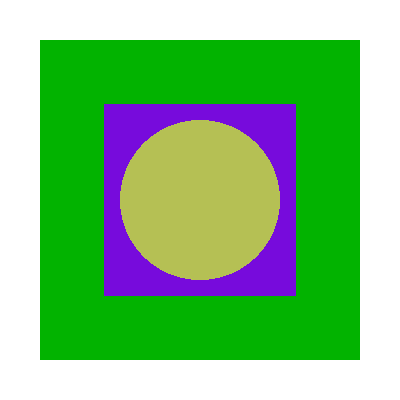

In [6]:
w = 25
plots = omc.Plots()

plot = omc.SlicePlot()
plot.basis = 'yz'
plot.origin = (0.0, 0.0, 0.0)
plot.width = (w,w)
plot.pixels = (400, 400)
plot.color_by= 'cell'

plots.append(plot)
omc.plot_inline(plots)
